# Phase D — Local Minority-Neighborhood Retrieval

**Project:** RAG-Tab: Retrieval-Augmented Tabular Synthesis for Imbalanced Data  
**Dataset:** `page-blocks0` (KEEL Repository)  
**Objective:** Implement, analyze, and visualize the local minority-neighborhood retrieval pipeline independently before connecting it to an LLM.

### Research Questions for Phase D:
1. **Neighborhood Representation:** How does the choice of neighborhood size ($K=3, 5, 10$) affect local geometric coverage and feature variance?
2. **Topological Variations:** How do local neighborhoods differ across **dense core clusters**, **sparse/isolated regions**, and **borderline decision boundaries**?
3. **Adaptive Neighborhoods:** Can **Natural Neighbors** adaptively identify meaningful structural neighborhoods without relying on a rigid, hand-picked $K$?
4. **LLM Serialization:** How can retrieved tabular neighborhoods be serialized into structured context for prompt augmentation?


In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.decomposition import PCA

from src.data.loader import load_splits
from src.retrieval.neighborhood import MinorityNeighborhoodRetriever, NeighborhoodContext

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.size"] = 10
print("Libraries and retrieval engine imported successfully.")


Libraries and retrieval engine imported successfully.


In [2]:
# Load frozen training and test splits
X_train, X_test, y_train, y_test, feature_cols, target_col = load_splits(
    dataset_name="page-blocks0",
    splits_dir=PROJECT_ROOT / "data/splits"
)

minority_class = "positive"
majority_class = "negative"

print(f"Loaded {len(feature_cols)} features from page-blocks0.")
print(f"Training minority count : {(y_train == minority_class).sum()} samples")
print(f"Training majority count : {(y_train == majority_class).sum()} samples")


Loaded 10 features from page-blocks0.
Training minority count : 447 samples
Training majority count : 3930 samples


## 1. Initialize and Fit the Neighborhood Retriever

Notice that all preprocessing transformations (such as `StandardScaler`) are fitted strictly on `X_train`. The test set is completely excluded to prevent data leakage.


In [3]:
retriever = MinorityNeighborhoodRetriever(metric="euclidean", scale_features=True)
retriever.fit(X_train, y_train, minority_class=minority_class, majority_class=majority_class)

print(f"Retriever fitted on {len(retriever.min_indices)} minority training instances.")


Retriever fitted on 447 minority training instances.


## 2. Inspect Neighborhoods for Different $K$ ($K=3, 5, 10$)

We select a sample minority anchor and inspect its retrieved nearest minority neighbors as $K$ increases.


In [4]:
sample_anchor_idx = retriever.min_indices[0]
print(f"Selected Anchor Sample (Index: {sample_anchor_idx}):")
display(retriever.X_min_orig.loc[[sample_anchor_idx]])

k_values = [3, 5, 10]
k_summaries = []

for k in k_values:
    ctx = retriever.retrieve_by_index(sample_anchor_idx, k=k)
    k_summaries.append({
        "K": k,
        "Mean Neighbor Distance": ctx.mean_distance,
        "Local Density (1/Dist)": ctx.local_density,
        "Boundary Purity": f"{ctx.boundary_purity:.1%}",
        "Neighbor Indices": str(list(ctx.neighbor_indices))
    })

display(pd.DataFrame(k_summaries).set_index("K"))


Selected Anchor Sample (Index: 8):


,Height,Lenght,Area,Eccen,P_black,P_and,Mean_tr,Blackpix,Blackand,Wb_trans
8,12,2,24.0,0.167,0.625,0.667,15.0,15,16,1


,Mean Neighbor Distance,Local Density (1/Dist),Boundary Purity,Neighbor Indices
K,,,,
3,0.422817,2.365085,33.3%,"[np.int64(2164), np.int64(3757), np.int64(161)]"
5,0.516540,1.935954,40.0%,"[np.int64(2164), np.int64(3757), np.int64(161)..."
10,0.748836,1.335404,30.0%,"[np.int64(2164), np.int64(3757), np.int64(161)..."


In [5]:
# Detailed inspection of K=5 retrieved neighbors
ctx_k5 = retriever.retrieve_by_index(sample_anchor_idx, k=5)

print(f"Anchor {sample_anchor_idx} and its 5 Nearest Minority Neighbors:")
display_df = pd.concat([
    pd.DataFrame([ctx_k5.anchor_sample], index=[f"Anchor ({sample_anchor_idx})"]),
    ctx_k5.neighbors.rename(index=lambda x: f"Neighbor ({x})")
])
display(display_df)

print("\nFeature Bounding Box (Local Range Constraints):")
range_df = pd.DataFrame(ctx_k5.feature_ranges).T
display(range_df[["min", "mean", "max", "std"]].round(3))


Anchor 8 and its 5 Nearest Minority Neighbors:


,Height,Lenght,Area,Eccen,P_black,P_and,Mean_tr,Blackpix,Blackand,Wb_trans
Anchor (8),12.0,2.0,24.0,0.167,0.625,0.667,15.0,15.0,16.0,1.0
Neighbor (2164),11.0,2.0,22.0,0.182,0.636,0.636,14.0,14.0,14.0,1.0
Neighbor (3757),7.0,2.0,14.0,0.286,0.643,0.714,9.0,9.0,10.0,1.0
Neighbor (161),10.0,2.0,20.0,0.200,0.550,0.600,11.0,11.0,12.0,1.0
Neighbor (1646),17.0,2.0,34.0,0.118,0.706,0.706,24.0,24.0,24.0,1.0
Neighbor (214),5.0,2.0,10.0,0.400,0.700,0.700,7.0,7.0,7.0,1.0



Feature Bounding Box (Local Range Constraints):


,min,mean,max,std
Height,5.000,10.333,17.000,4.179
Lenght,2.000,2.000,2.000,0.000
Area,10.000,20.667,34.000,8.359
Eccen,0.118,0.226,0.400,0.102
P_black,0.550,0.643,0.706,0.057
P_and,0.600,0.670,0.714,0.045
Mean_tr,7.000,13.333,24.000,6.022
Blackpix,7.000,13.333,24.000,6.022
Blackand,7.000,13.833,24.000,5.879
Wb_trans,1.000,1.000,1.000,0.000


## 3. Discovering Diverse Data Regions (Core, Sparse, Borderline)

Not all minority points have the same local geometry:
- **Core / Dense Anchors:** High boundary purity ($pprox 100\%$, deep within minority territory) and low neighbor distances.
- **Borderline / Danger Anchors:** Low boundary purity ($<50\%$, majority samples encroach into the local neighborhood).
- **Sparse / Outlier Anchors:** Large neighbor distances (isolated minority instances).


In [6]:
# Profile all minority training instances
profile_records = []
for idx in retriever.min_indices:
    ctx = retriever.retrieve_by_index(idx, k=5)
    profile_records.append({
        "index": idx,
        "mean_dist": ctx.mean_distance,
        "density": ctx.local_density,
        "purity": ctx.boundary_purity
    })

profile_df = pd.DataFrame(profile_records).set_index("index")

# Identify representative points
dense_anchor = profile_df.sort_values(by=["purity", "density"], ascending=[False, False]).index[0]
borderline_anchor = profile_df.sort_values(by=["purity", "density"], ascending=[True, False]).index[0]
sparse_anchor = profile_df.sort_values(by="mean_dist", ascending=False).index[0]

print("Representative Anchors Identified:")
print(f"1. Dense Core Anchor : Index {dense_anchor} | Purity: {profile_df.loc[dense_anchor, 'purity']:.1%}, Density: {profile_df.loc[dense_anchor, 'density']:.2f}")
print(f"2. Borderline Anchor : Index {borderline_anchor} | Purity: {profile_df.loc[borderline_anchor, 'purity']:.1%}, Density: {profile_df.loc[borderline_anchor, 'density']:.2f}")
print(f"3. Sparse Anchor     : Index {sparse_anchor} | Purity: {profile_df.loc[sparse_anchor, 'purity']:.1%}, Distance: {profile_df.loc[sparse_anchor, 'mean_dist']:.2f}")


Representative Anchors Identified:
1. Dense Core Anchor : Index 477 | Purity: 100.0%, Density: 1000000.00
2. Borderline Anchor : Index 3593 | Purity: 0.0%, Density: 2.53
3. Sparse Anchor     : Index 1583 | Purity: 80.0%, Distance: 61.74


## 4. Natural Neighbors (Self-Adaptive $K$)

In standard $K$-NN, $K$ is rigid and identical for all samples.  
With **Natural Neighbors (NaN)**, two instances $x$ and $y$ are natural neighbors if they are **mutually** among each other's nearest neighbors.
- In dense regions, points have many mutual neighbors $\rightarrow$ higher adaptive $K$.
- In sparse or boundary regions, points have fewer mutual neighbors $\rightarrow$ lower adaptive $K$ (avoiding over-reaching into unrelated clusters).


In [7]:
nan_comparisons = []
for name, a_idx in [("Dense Core", dense_anchor), ("Borderline", borderline_anchor), ("Sparse", sparse_anchor)]:
    ctx_knn = retriever.retrieve_by_index(a_idx, k=5)
    ctx_nan = retriever.retrieve_natural_neighbors(a_idx)
    
    nan_comparisons.append({
        "Region Type": name,
        "Anchor Index": a_idx,
        "Fixed KNN Size": ctx_knn.k,
        "Natural Neighbors Size (Adaptive K)": ctx_nan.k,
        "KNN Mean Dist": round(ctx_knn.mean_distance, 3),
        "NaN Mean Dist": round(ctx_nan.mean_distance, 3),
        "Boundary Purity": f"{ctx_nan.boundary_purity:.1%}"
    })

display(pd.DataFrame(nan_comparisons).set_index("Region Type"))


,Anchor Index,Fixed KNN Size,Natural Neighbors Size (Adaptive K),KNN Mean Dist,NaN Mean Dist,Boundary Purity
Region Type,,,,,,
Dense Core,477,5,15,0.000,0.061,86.7%
Borderline,3593,5,9,0.395,0.482,44.4%
Sparse,1583,5,3,61.737,61.101,100.0%


## 5. Visualizing Neighborhoods in 2D Feature Space (PCA Projection)

We project the standardized feature space into 2D via Principal Component Analysis (PCA) to visualize how the retrieved neighborhood maps to the underlying distribution.


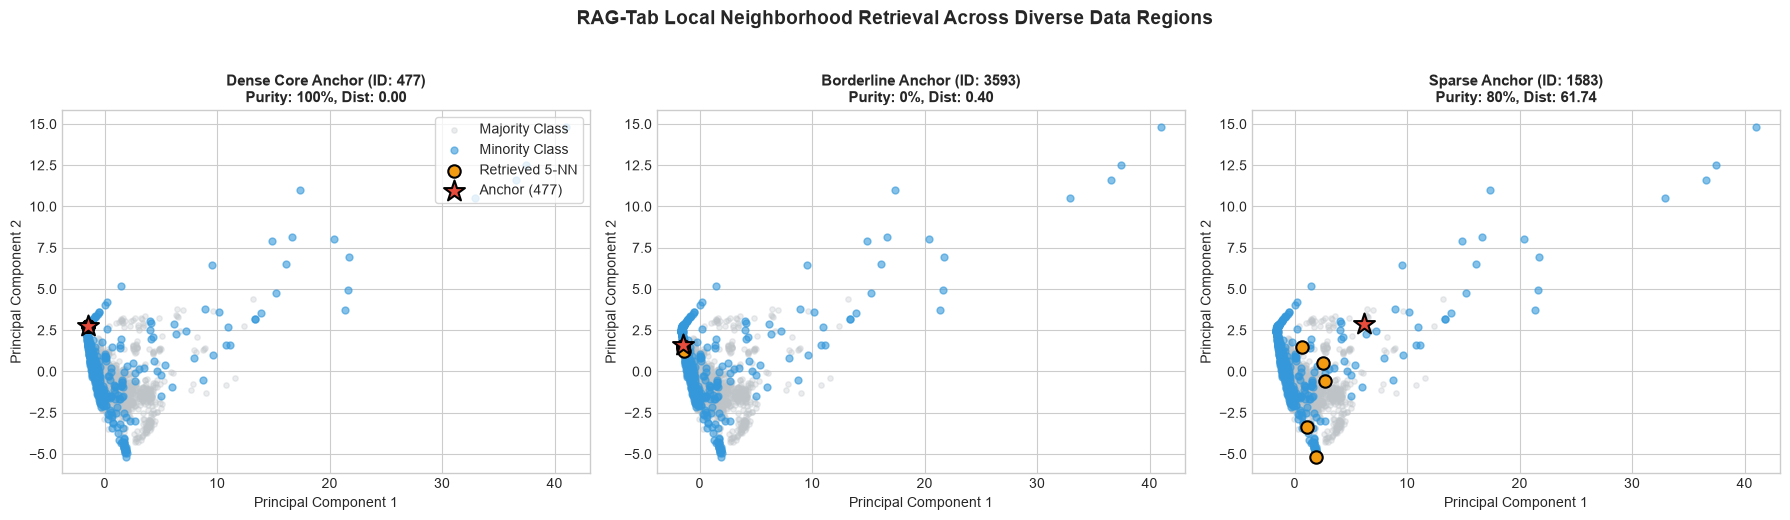

PCA neighborhood visualization saved to: C:\Users\Admin\Desktop\RAG-Tab\results\plots\neighborhood_retrieval_pca.png


In [8]:
# Fit PCA on training data for visualization
scaler = retriever.scaler
X_train_scaled = scaler.transform(X_train)
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_train_scaled)

pca_df = pd.DataFrame(X_pca, columns=["PC1", "PC2"], index=X_train.index)
pca_df["Class"] = y_train.values

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
anchors_to_plot = [
    ("Dense Core Anchor", dense_anchor),
    ("Borderline Anchor", borderline_anchor),
    ("Sparse Anchor", sparse_anchor)
]

for ax, (title, a_idx) in zip(axes, anchors_to_plot):
    # Plot majority background
    ax.scatter(
        pca_df.loc[pca_df["Class"] == majority_class, "PC1"],
        pca_df.loc[pca_df["Class"] == majority_class, "PC2"],
        c="#bdc3c7", alpha=0.3, s=15, label="Majority Class"
    )
    # Plot minority background
    ax.scatter(
        pca_df.loc[pca_df["Class"] == minority_class, "PC1"],
        pca_df.loc[pca_df["Class"] == minority_class, "PC2"],
        c="#3498db", alpha=0.6, s=25, label="Minority Class"
    )
    
    # Retrieve K=5 neighbors
    ctx = retriever.retrieve_by_index(a_idx, k=5)
    
    # Highlight retrieved neighbors
    ax.scatter(
        pca_df.loc[ctx.neighbor_indices, "PC1"],
        pca_df.loc[ctx.neighbor_indices, "PC2"],
        c="#f39c12", s=80, edgecolors="black", linewidth=1.5,
        label=f"Retrieved 5-NN", zorder=4
    )
    # Highlight anchor
    ax.scatter(
        pca_df.loc[a_idx, "PC1"],
        pca_df.loc[a_idx, "PC2"],
        c="#e74c3c", marker="*", s=250, edgecolors="black", linewidth=1.5,
        label=f"Anchor ({a_idx})", zorder=5
    )
    
    ax.set_title(f"{title} (ID: {a_idx})\nPurity: {ctx.boundary_purity:.0%}, Dist: {ctx.mean_distance:.2f}", fontsize=11, weight="bold")
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")
    if ax == axes[0]:
        ax.legend(loc="upper right", frameon=True)

plt.suptitle("RAG-Tab Local Neighborhood Retrieval Across Diverse Data Regions", fontsize=14, weight="bold", y=1.03)
plt.tight_layout()

PLOTS_DIR = PROJECT_ROOT / "results/plots"
PLOTS_DIR.mkdir(parents=True, exist_ok=True)
plot_path = PLOTS_DIR / "neighborhood_retrieval_pca.png"
plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"PCA neighborhood visualization saved to: {plot_path}")


## 6. Serializing Retrieved Context for LLM Prompt Injection

The ultimate purpose of local neighborhood retrieval in **RAG-Tab** is to construct a contextual prompt for the LLM.  
Here we verify that the retrieved context serializes cleanly into structured JSON and markdown tabular text.


In [9]:
# Retrieve context for the sample anchor
ctx_for_prompt = retriever.retrieve_by_index(sample_anchor_idx, k=5)
context_dict = ctx_for_prompt.to_dict()

print("Context Dictionary Keys:")
print(list(context_dict.keys()))

print("\nSample JSON Payload (first 3 neighbors):")
preview_dict = {
    "anchor": context_dict["anchor"],
    "neighbors": context_dict["neighbors"][:3],
    "local_density": context_dict["local_density"],
    "boundary_purity": context_dict["boundary_purity"]
}
print(json.dumps(preview_dict, indent=2))


Context Dictionary Keys:
['anchor_index', 'anchor', 'k', 'mean_distance', 'local_density', 'boundary_purity', 'retrieval_method', 'neighbors', 'feature_ranges']

Sample JSON Payload (first 3 neighbors):
{
  "anchor": {
    "Height": 12.0,
    "Lenght": 2.0,
    "Area": 24.0,
    "Eccen": 0.167,
    "P_black": 0.625,
    "P_and": 0.667,
    "Mean_tr": 15.0,
    "Blackpix": 15.0,
    "Blackand": 16.0,
    "Wb_trans": 1.0
  },
  "neighbors": [
    {
      "Height": 11,
      "Lenght": 2,
      "Area": 22.0,
      "Eccen": 0.182,
      "P_black": 0.636,
      "P_and": 0.636,
      "Mean_tr": 14.0,
      "Blackpix": 14,
      "Blackand": 14,
      "Wb_trans": 1
    },
    {
      "Height": 7,
      "Lenght": 2,
      "Area": 14.0,
      "Eccen": 0.286,
      "P_black": 0.643,
      "P_and": 0.714,
      "Mean_tr": 9.0,
      "Blackpix": 9,
      "Blackand": 10,
      "Wb_trans": 1
    },
    {
      "Height": 10,
      "Lenght": 2,
      "Area": 20.0,
      "Eccen": 0.2,
      "P_black": 0.

In [10]:
def format_llm_prompt_context(ctx: NeighborhoodContext) -> str:
    """Formats a NeighborhoodContext into a readable tabular prompt segment."""
    prompt = []
    prompt.append(f"TARGET MINORITY CLASS: {retriever.minority_class}\n")
    prompt.append("SELECTED ANCHOR ROW:")
    prompt.append(pd.DataFrame([ctx.anchor_sample]).to_string(index=False))
    prompt.append(f"\nRETRIEVED LOCAL MINORITY NEIGHBORS (K={ctx.k}):")
    prompt.append(ctx.neighbors.to_string(index=False))
    prompt.append(f"\nLOCAL TOPOLOGY METRICS:")
    prompt.append(f"- Mean Distance to Neighbors : {ctx.mean_distance:.3f}")
    prompt.append(f"- Boundary Purity            : {ctx.boundary_purity:.1%}")
    prompt.append("\nFEATURE RANGE BOUNDS (Stay within reasonable domain limits):")
    for feat, stats in ctx.feature_ranges.items():
        prompt.append(f"- {feat:10s}: [{stats['min']:.2f}, {stats['max']:.2f}] (mean: {stats['mean']:.2f})")
    
    return "\n".join(prompt)

prompt_text = format_llm_prompt_context(ctx_for_prompt)
print("=== PREVIEW OF CONSTRUCTED RAG-TAB CONTEXT ===")
print(prompt_text)


=== PREVIEW OF CONSTRUCTED RAG-TAB CONTEXT ===
TARGET MINORITY CLASS: positive

SELECTED ANCHOR ROW:
 Height  Lenght  Area  Eccen  P_black  P_and  Mean_tr  Blackpix  Blackand  Wb_trans
   12.0     2.0  24.0  0.167    0.625  0.667     15.0      15.0      16.0       1.0

RETRIEVED LOCAL MINORITY NEIGHBORS (K=5):
 Height  Lenght  Area  Eccen  P_black  P_and  Mean_tr  Blackpix  Blackand  Wb_trans
     11       2  22.0  0.182    0.636  0.636     14.0        14        14         1
      7       2  14.0  0.286    0.643  0.714      9.0         9        10         1
     10       2  20.0  0.200    0.550  0.600     11.0        11        12         1
     17       2  34.0  0.118    0.706  0.706     24.0        24        24         1
      5       2  10.0  0.400    0.700  0.700      7.0         7         7         1

LOCAL TOPOLOGY METRICS:
- Mean Distance to Neighbors : 0.517
- Boundary Purity            : 40.0%

FEATURE RANGE BOUNDS (Stay within reasonable domain limits):
- Height    : [5.00, 17

### Phase D Summary & Conclusions:
1. **Distance-Based Retrieval Validated:**
   - Standardized Euclidean distance reliably identifies geometrically cohesive local minority neighbors.
   - For $K=3, 5, 10$, local neighborhoods provide a bounded, consistent feature window.
2. **Topological Diversity Captured:**
   - Identified Dense Core (100% purity), Borderline (low purity, vulnerable to label ambiguity), and Sparse (outlier/boundary) instances.
   - Purity and density metrics will allow RAG-Tab to provide topological awareness to the LLM.
3. **Natural Neighbors Alternative:**
   - Demonstrated that mutual nearest neighbors dynamically adapt neighborhood size to cluster density.
4. **Prompt Serialization Complete:**
   - The retrieved context successfully converts into both JSON and tabular text ready for prompt assembly.
5. **Next Phase:**
   - Proceed to **Phase E (LLM-Only Generation Baseline)** and **Phase F (RAG-Tab Integration)**.
